# Trabajo Práctico N° 3

**Materia:** Minería de Datos
**Año:** 2026
**Integrantes:** Franco Renna y Franco Esparza

Clasificación multiclase sobre `crop_recommendation_geo.csv`: estimamos `clase`, el cultivo recomendado entre 10 posibles, a partir de 16 variables de suelo y clima.

Comparamos tres modelos: SVM con kernel lineal, SVM con kernel gaussiano (RBF) y Random Forest.

Usamos `random_state=13` en las particiones, en la validación cruzada y en los modelos.

## Configuración

In [1]:
# Manejo de datos
import time

import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de los datos
from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Modelos
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

# Semilla que indica el enunciado, usada en las particiones, en la validación
# cruzada y en los modelos
SEMILLA = 13

## Actividad 1. Preparación de los datos

### Carga y estructura

El archivo usa `;` como separador de columnas y la coma como separador decimal, así que hay que indicarle las dos cosas a `read_csv`.

In [2]:
cultivos = pd.read_csv("crop_recommendation/crop_recommendation_geo.csv",
                       sep=";", decimal=",")

print("Tabla 1. Primeras filas del conjunto de cultivos")
cultivos.head()

Tabla 1. Primeras filas del conjunto de cultivos


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


In [3]:
cultivos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

In [4]:
print("Tabla 2. Medidas resumen de las variables predictoras")
cultivos.describe().T.round(3)

Tabla 2. Medidas resumen de las variables predictoras


,count,mean,std,min,25%,50%,75%,max
N,50004.0,1.806,0.962,0.265,1.098,1.632,2.272,15.098
P,50004.0,10.306,11.115,0.000,3.680,6.668,12.885,180.000
exch_bases,50004.0,17.864,11.976,0.100,7.000,16.000,26.500,143.000
ph,50003.0,6.479,1.018,4.050,5.550,6.500,7.350,25.317
soc,50004.0,24.340,26.462,1.017,11.017,18.117,27.183,322.817
arcilla,50004.0,31.240,8.045,2.400,25.633,31.033,36.767,142.383
arena,50004.0,36.902,13.559,0.883,28.017,34.683,45.033,94.500
cec,50003.0,20.457,7.745,3.717,15.550,19.550,24.233,70.817
temperatura,50004.0,19.240,7.718,-7.377,14.217,21.962,25.789,44.626
temp_min_mensual,50004.0,11.908,12.633,-27.869,3.103,16.445,22.097,27.918


El conjunto tiene 50.004 filas y 17 columnas: 16 variables predictoras numéricas y la variable objetivo `clase`, que es de texto. El enunciado la nombra `temp_mim_mensual`, pero en el archivo la columna se llama `temp_min_mensual`.

En la salida de `info()` vemos que `ph`, `cec` y `humedad` tienen 50.003 valores en lugar de 50.004: hay faltantes. Los contamos y los tratamos más abajo.

La Tabla 2 muestra cuatro máximos que no pueden ser:

- `ph` llega a 25.317, cuando la escala de pH va de 0 a 14 y el percentil 75 es 7.35.
- `humedad` llega a 148.141, cuando es una humedad relativa en porcentaje.
- `arcilla` llega a 142.383, también un porcentaje.
- `temp_max_mensual` llega a 53.006, con un percentil 75 de 28.98.

También hay mínimos negativos en `temperatura` (−7.377), `temp_min_mensual` (−27.869) y `elevacion` (−161). Esos sí son posibles: hay lugares bajo el nivel del mar y meses con temperaturas bajo cero.

### Distribución de la variable objetivo

In [5]:
balance = pd.DataFrame({
    "Cantidad": cultivos["clase"].value_counts(),
    "Porcentaje": (cultivos["clase"].value_counts(normalize=True) * 100).round(2),
})

print("Tabla 3. Balance de la variable objetivo")
balance

Tabla 3. Balance de la variable objetivo


,Cantidad,Porcentaje
clase,,
cafe,5002,10.0
arroz,5001,10.0
manzana,5001,10.0
maiz,5000,10.0
garbanzo,5000,10.0
algodon,5000,10.0
banana,5000,10.0
frijol,5000,10.0
coco,5000,10.0


Las diez clases tienen 5.000 muestras cada una, salvo `cafe` con 5.002 y `arroz` y `manzana` con 5.001. El conjunto está repartido en partes iguales, con un 10 % por cultivo.

El enunciado pide el promedio `weighted` porque habla de un leve desbalance. Con esta distribución, `weighted` y `macro` van a dar prácticamente el mismo número, porque todas las clases pesan casi lo mismo.

### Distribución de las variables predictoras

**Hipótesis previa:** son medidas de suelo y clima tomadas en lugares distintos del mundo, así que esperamos distribuciones asimétricas en las del suelo (la mayoría de los sitios con poco nutriente y unos pocos con mucho) y varias modas en las climáticas, porque los diez cultivos crecen en climas diferentes.

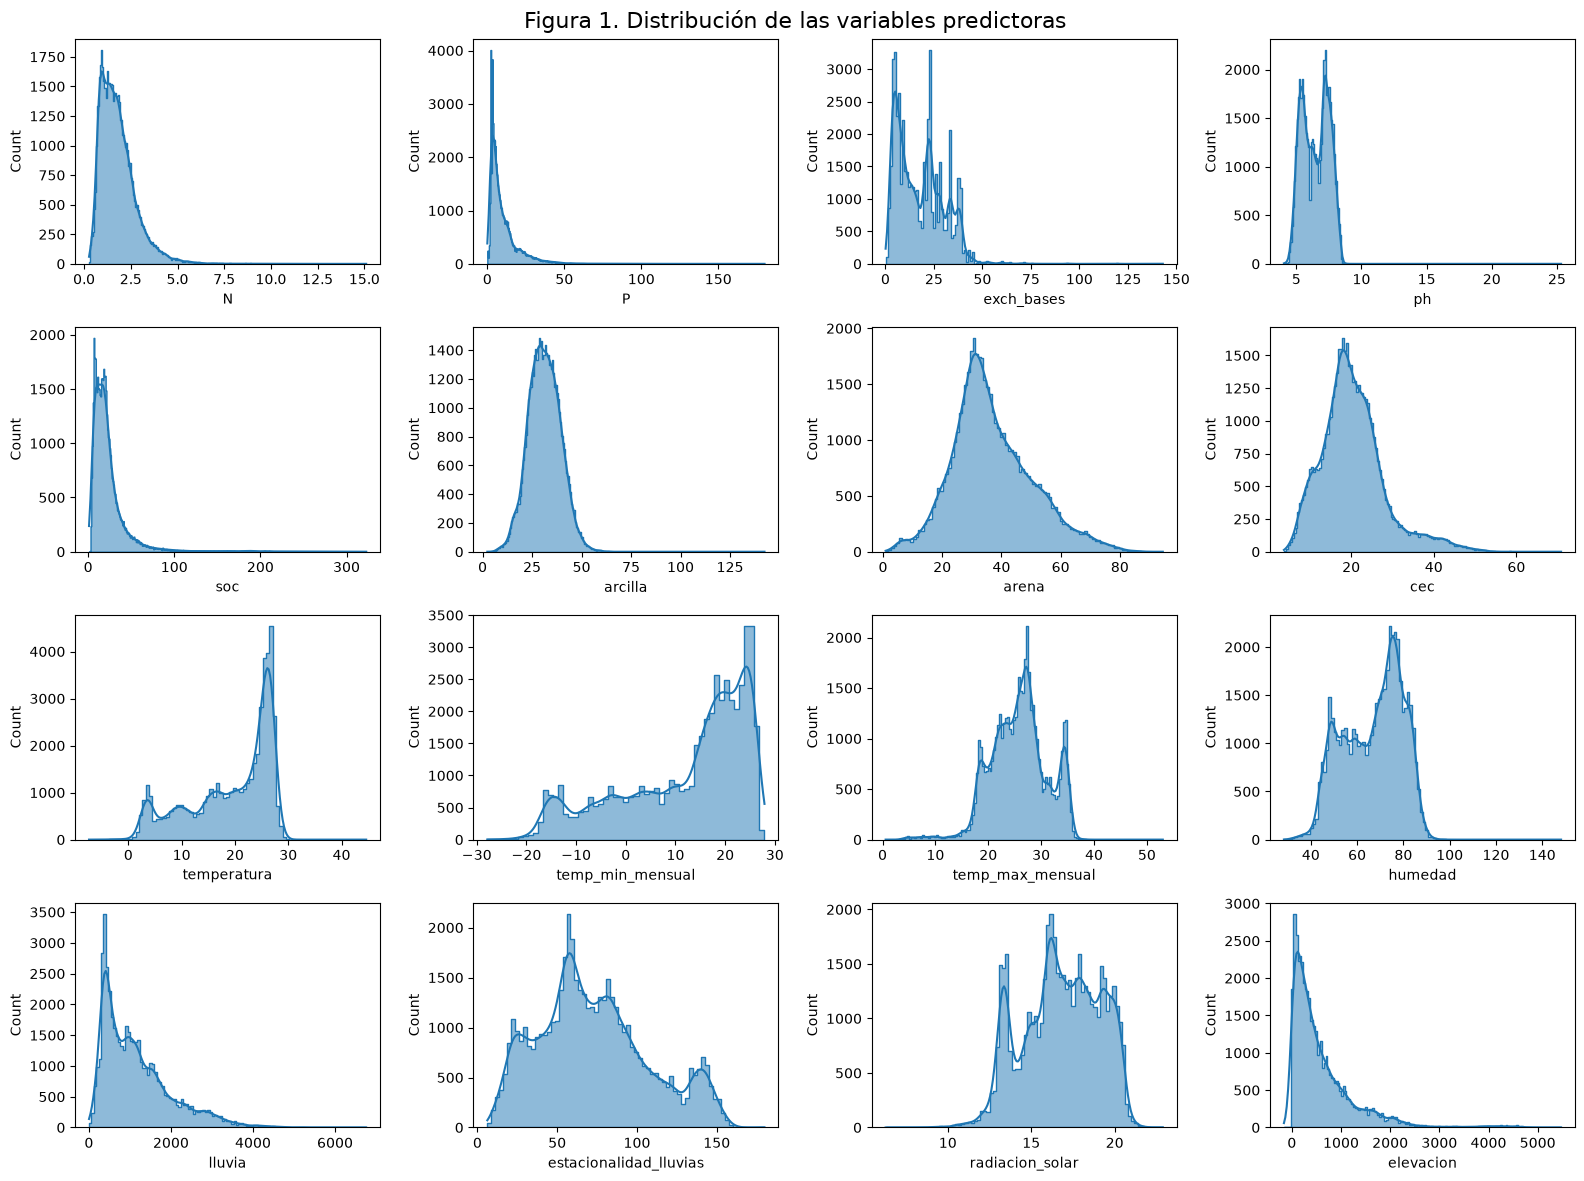

In [6]:
predictoras = cultivos.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 12))
for i, col in enumerate(predictoras, 1):
    sns.histplot(data=cultivos, x=col, kde=True, element="step",
                 ax=axes.flatten()[i-1])

plt.suptitle("Figura 1. Distribución de las variables predictoras", fontsize=16)
plt.tight_layout()
plt.show()

La hipótesis se cumple en las dos partes. `N`, `P`, `soc`, `lluvia` y `elevacion` se amontonan contra el borde izquierdo y estiran una cola larga hacia la derecha. `temperatura`, `temp_min_mensual`, `humedad`, `estacionalidad_lluvias` y `radiacion_solar` tienen dos o tres picos separados, que es lo que esperábamos de climas distintos conviviendo en el mismo conjunto. `arcilla` y `arena` son las más parecidas a una campana.

La figura también deja ver los valores imposibles de la Tabla 2. En `ph`, `arcilla`, `humedad` y `temp_max_mensual` el eje horizontal se estira mucho más allá de donde están las barras: todo `ph` está entre 4 y 9, pero el eje llega a 25 porque hay algún dato suelto ahí.

### Correlación entre las variables

**Hipótesis previa:** esperamos que las tres temperaturas estén muy correlacionadas entre sí, porque las tres miden lo mismo en momentos distintos del año, y que `lluvia` y `humedad` también vayan juntas.

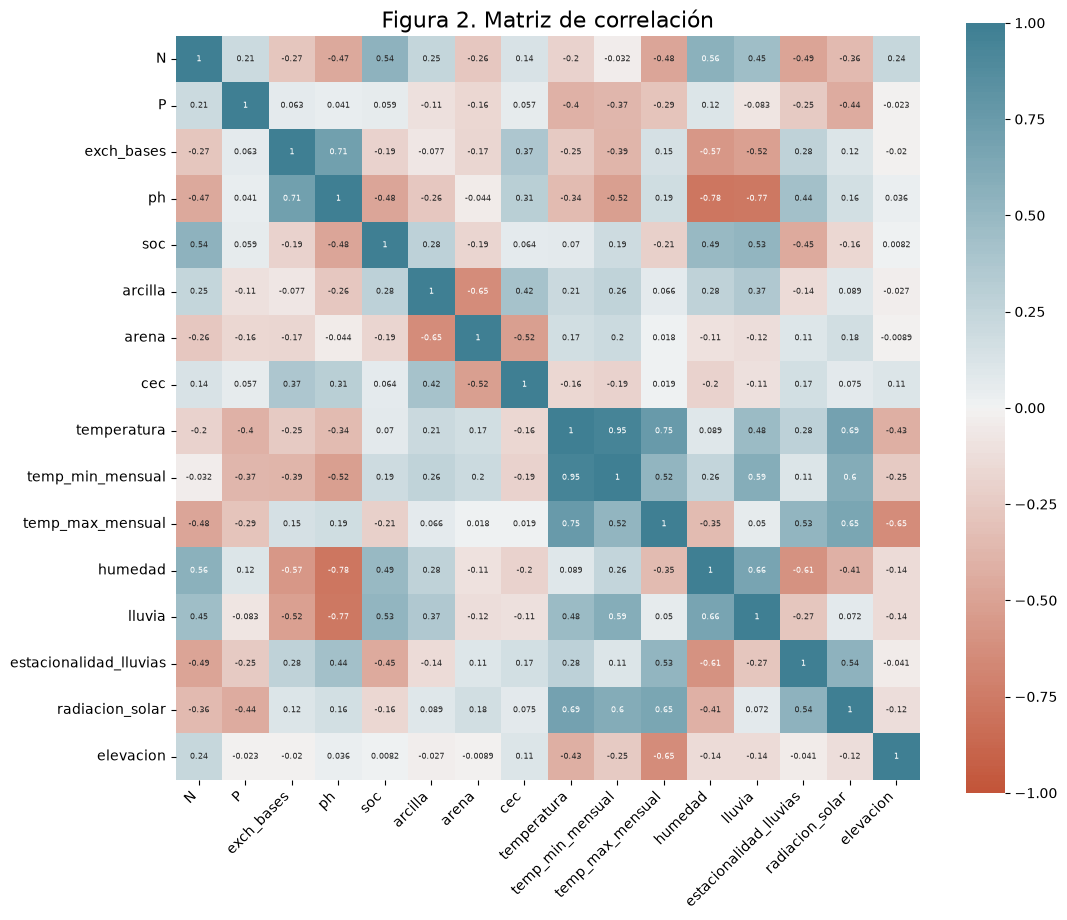

In [7]:
plt.figure(figsize=(12, 10))
corr = cultivos[predictoras].corr(method="pearson")
ax = sns.heatmap(
    corr,
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True,
    annot=True,
    annot_kws={"size": 6}
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment="right"
)
plt.title("Figura 2. Matriz de correlación", fontsize=16)
plt.show()

Se cumple lo que esperábamos: `temperatura` con `temp_min_mensual` da 0.95 y con `temp_max_mensual` 0.75, y `humedad` con `lluvia` da 0.66.

Lo que no esperábamos es que el `ph` esté tan atado al clima: −0.78 con `humedad` y −0.77 con `lluvia`. Dentro del suelo, `ph` y `exch_bases` dan 0.71.

Ningún par llega a 1, así que no hay dos columnas que sean la misma medida repetida. Dejamos las 16 variables.

### Valores faltantes

El enunciado pide indicar en qué columnas están y qué estrategia usamos.

In [8]:
print(cultivos.isna().sum())
print()
print("Filas con al menos un faltante:", cultivos.isna().any(axis=1).sum())
print()
print("Tabla 4. La única fila con valores faltantes")
cultivos[cultivos.isna().any(axis=1)]

N                         0
P                         0
exch_bases                0
ph                        1
soc                       0
arcilla                   0
arena                     0
cec                       1
temperatura               0
temp_min_mensual          0
temp_max_mensual          0
humedad                   1
lluvia                    0
estacionalidad_lluvias    0
radiacion_solar           0
elevacion                 0
clase                     0
dtype: int64

Filas con al menos un faltante: 1

Tabla 4. La única fila con valores faltantes


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Los faltantes están en `ph`, `cec` y `humedad`, uno en cada columna, y los tres son de la **misma fila**: la 25085, un `cafe`. Es 1 fila entre 50.004.

**Decisión: la eliminamos.** Imputar por la media o la mediana tiene sentido cuando falta un valor suelto y el resto de la fila aporta información. Acá habría que inventar tres de las dieciséis variables de la misma muestra, y dos de ellas (`ph` y `humedad`) son de las que más se relacionan con el resto según la Figura 2. Por una fila entre 50.004 no vale la pena.

In [9]:
cultivos = cultivos.dropna()
print("Filas tras eliminar los faltantes:", len(cultivos))

Filas tras eliminar los faltantes: 50003


### Registros duplicados

In [10]:
print("Registros duplicados:", cultivos.duplicated().sum())
print()
print("Filas involucradas, por cultivo:")
print(cultivos[cultivos.duplicated(keep=False)]["clase"].value_counts())

Registros duplicados: 198

Filas involucradas, por cultivo:
clase
lenteja     218
manzana     110
algodon      28
garbanzo     24
maiz          6
frijol        6
arroz         4
Name: count, dtype: int64


Hay **198 duplicados**: filas que repiten las 17 columnas, con todos sus decimales. Que 16 medidas de suelo y clima coincidan hasta el tercer decimal no pasa por casualidad, son cargas repetidas del mismo registro. No están repartidos parejo: de las 396 filas involucradas, 218 son de `lenteja` y 110 de `manzana`.

**Decisión: los eliminamos con `drop_duplicates()`.** Si una fila repetida quedara en dos folds distintos de la validación cruzada, el modelo se estaría evaluando con una muestra que ya vio al entrenar, y la métrica saldría mejor de lo que corresponde.

In [11]:
cultivos = cultivos.drop_duplicates()
print("Filas tras eliminar los duplicados:", len(cultivos))

Filas tras eliminar los duplicados: 49805


### Valores atípicos

Separamos dos cosas distintas. Primero los valores **imposibles**, que están fuera del rango que la variable puede tomar; después los **atípicos estadísticos**, que son valores posibles pero lejanos al resto.

Buscamos los imposibles en las cuatro variables que tienen un tope conocido: el pH, que va de 0 a 14, y `arcilla`, `arena` y `humedad`, que son porcentajes.

In [12]:
imposibles = ((cultivos["ph"] > 14) | (cultivos["humedad"] > 100) |
              (cultivos["arcilla"] > 100) | (cultivos["arena"] > 100))

print("Filas con algún valor imposible:", imposibles.sum())
print()
print("Tabla 5. Filas con valores fuera del rango posible")
cultivos[imposibles]

Filas con algún valor imposible: 2

Tabla 5. Filas con valores fuera del rango posible


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Son 2 filas. La 25111 tiene `ph` 25.317 y la 30012 tiene `ph` 18.017, `arcilla` 142.383 y `humedad` 148.141, las tres imposibles a la vez. Esa misma fila además se queda con los máximos del conjunto en `temperatura` (44.626) y `temp_max_mensual` (53.006), que son los que veíamos en la Tabla 2, y con el mínimo de `radiacion_solar` (6.274).

**Decisión: las eliminamos.** No es un dato raro pero posible: es una medición rota. Corregir solo el valor imposible y dejar el resto de la fila tampoco sirve, porque en la 30012 está mal casi todo.

In [13]:
cultivos = cultivos[~imposibles]
print("Filas tras eliminar los valores imposibles:", len(cultivos))
print("Máximos que quedan -> ph:", cultivos["ph"].max(),
      "| humedad:", cultivos["humedad"].max(),
      "| arcilla:", cultivos["arcilla"].max(),
      "| temp_max_mensual:", cultivos["temp_max_mensual"].max())

Filas tras eliminar los valores imposibles: 49803


Máximos que quedan -> ph: 8.95 | humedad: 97.373 | arcilla: 68.633 | temp_max_mensual: 38.221


Ahora los atípicos estadísticos, con el criterio de rango intercuartílico: queda fuera todo lo que esté a más de 1.5 veces el IQR por debajo del primer cuartil o por encima del tercero.

**Hipótesis previa:** en la Figura 1 varias variables tenían cola larga a la derecha, así que esperamos bastantes atípicos por encima en `soc`, `P`, `lluvia` y `elevacion`. Y como cada cultivo crece en un ambiente distinto, esperamos que no estén repartidos parejo entre los diez, sino concentrados en algunos.

In [14]:
q1 = cultivos[predictoras].quantile(0.25)
q3 = cultivos[predictoras].quantile(0.75)
iqr = q3 - q1

bajos = (cultivos[predictoras] < (q1 - 1.5 * iqr)).sum()
altos = (cultivos[predictoras] > (q3 + 1.5 * iqr)).sum()

atipicos = pd.DataFrame({
    "Por debajo": bajos,
    "Por encima": altos,
    "Total": bajos + altos,
    "Porcentaje": ((bajos + altos) / len(cultivos) * 100).round(2),
}).sort_values("Total", ascending=False)

print("Tabla 6. Valores atípicos por el criterio IQR")
atipicos

Tabla 6. Valores atípicos por el criterio IQR


,Por debajo,Por encima,Total,Porcentaje
soc,0,3645,3645,7.32
P,0,3485,3485,7.00
elevacion,0,2821,2821,5.66
cec,0,2165,2165,4.35
N,0,1474,1474,2.96
lluvia,0,1355,1355,2.72
arena,17,825,842,1.69
temp_max_mensual,534,0,534,1.07
arcilla,86,197,283,0.57
exch_bases,0,181,181,0.36


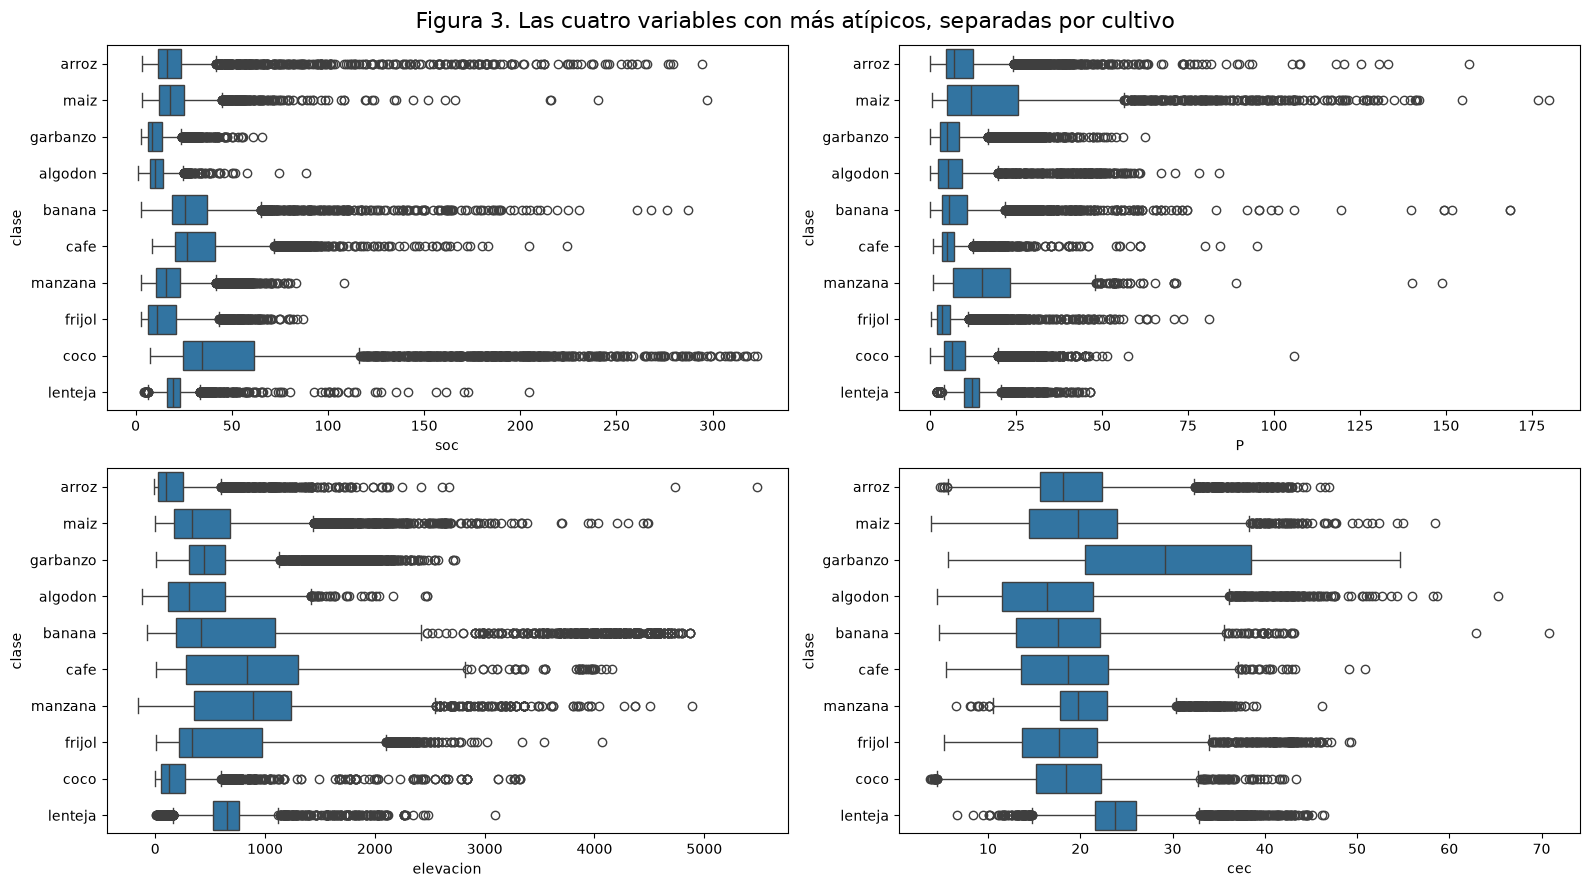

In [15]:
peores = atipicos.index[:4]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 9))
for i, col in enumerate(peores, 1):
    sns.boxplot(data=cultivos, x=col, y="clase", ax=axes.flatten()[i-1])

plt.suptitle("Figura 3. Las cuatro variables con más atípicos, separadas por cultivo",
             fontsize=16)
plt.tight_layout()
plt.show()

La hipótesis se cumple en las dos partes. Los cuatro primeros puestos de la Tabla 6 son `soc` (3.645 casos, 7.32 %), `P` (3.485), `elevacion` (2.821) y `cec` (2.165), todos por encima, que son justo las variables de cola larga de la Figura 1. `ph` y `humedad` quedaron con cero atípicos una vez que sacamos las dos filas rotas.

Y en la Figura 3 se ve que están concentrados por cultivo. La caja de `soc` de `coco` está corrida a la derecha respecto de las demás y es la que más puntos sueltos arrastra; en `cec`, la caja de `garbanzo` queda a la derecha de todas las otras; `elevacion` tiene sus valores altos en `cafe`, `manzana` y `banana`; y `P`, en `maiz` y `manzana`.

**Decisión: los conservamos.** No son errores de carga: son las condiciones propias de cada cultivo, que es lo que los modelos tienen que aprender para distinguirlos. Recortarlos borraría la diferencia que hace reconocible al `coco` o al `garbanzo`.

In [16]:
print("Conjunto limpio:", cultivos.shape)
print()

balance_limpio = pd.DataFrame({
    "Cantidad": cultivos["clase"].value_counts(),
    "Porcentaje": (cultivos["clase"].value_counts(normalize=True) * 100).round(2),
})

print("Tabla 7. Balance de la variable objetivo tras la limpieza")
balance_limpio

Conjunto limpio: (49803, 17)

Tabla 7. Balance de la variable objetivo tras la limpieza


,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Quedan **49.803 filas**: salieron 1 por faltantes, 198 por duplicados y 2 por valores imposibles.

Como los duplicados no estaban repartidos parejo, la limpieza dejó un desbalance que antes no existía: `lenteja` baja a 4.891 (9.82 %) mientras `banana`, `cafe` y `coco` se quedan con 5.000 (10.04 %). Es la diferencia leve de la que habla el enunciado cuando pide el promedio `weighted`.

### Codificación de la variable objetivo

Separamos las 16 predictoras de la variable objetivo y pasamos `clase` a números con `LabelEncoder`, como pide el enunciado.

In [17]:
X = cultivos.drop(columns="clase")
codificador = LabelEncoder()
y = codificador.fit_transform(cultivos["clase"])

print("X:", X.shape, "| y:", y.shape)
print()

print("Tabla 8. Códigos asignados a cada cultivo")
pd.DataFrame({"Código": range(len(codificador.classes_)),
              "Cultivo": codificador.classes_})

X: (49803, 16) | y: (49803,)

Tabla 8. Códigos asignados a cada cultivo


,Código,Cultivo
0,0,algodon
1,1,arroz
2,2,banana
3,3,cafe
4,4,coco
5,5,frijol
6,6,garbanzo
7,7,lenteja
8,8,maiz
9,9,manzana


`LabelEncoder` asigna un número por cultivo siguiendo el orden alfabético: `algodon` es 0 y `manzana` es 9.

Acá no hace falta la codificación one-hot que usamos en el TP2 para `State`. Ahí el problema era que una variable **predictora** sin orden quedara con distancias falsas (que `maiz` estuviera a 8 de `algodon` y a 1 de `lenteja`). `clase` no es una predictora: es lo que hay que estimar, y los modelos la tratan como una etiqueta, no como un número con el que se pueda calcular. Guardamos `codificador.classes_` para volver a los nombres en las matrices de confusión.

### Estandarización

El enunciado pide estandarizar porque SVM es sensible a la escala. Se nota mirando la Tabla 2: `lluvia` llega a 6.759 y `N` no pasa de 15, así que sin estandarizar la distancia entre dos muestras la decidiría casi sola la lluvia.

In [18]:
escalador = StandardScaler().set_output(transform="pandas")
X_std = escalador.fit_transform(X)

print("Tabla 9. Medidas resumen de las variables estandarizadas")
X_std.describe().T.round(3)

Tabla 9. Medidas resumen de las variables estandarizadas


,count,mean,std,min,25%,50%,75%,max
N,49803.0,0.0,1.0,-1.601,-0.736,-0.183,0.485,13.810
P,49803.0,0.0,1.0,-0.926,-0.595,-0.328,0.228,15.254
exch_bases,49803.0,-0.0,1.0,-1.405,-0.904,-0.153,0.723,10.446
ph,49803.0,0.0,1.0,-2.394,-0.913,0.025,0.864,2.444
soc,49803.0,0.0,1.0,-0.881,-0.504,-0.236,0.108,11.260
arcilla,49803.0,0.0,1.0,-3.592,-0.701,-0.024,0.688,4.656
arena,49803.0,-0.0,1.0,-2.656,-0.655,-0.163,0.600,4.244
cec,49803.0,0.0,1.0,-2.158,-0.636,-0.118,0.484,6.499
temperatura,49803.0,0.0,1.0,-3.466,-0.648,0.356,0.847,1.442
temp_min_mensual,49803.0,0.0,1.0,-3.165,-0.694,0.359,0.805,1.266


Las 16 columnas quedaron con media 0 y desvío 1, que es lo que tiene que pasar.

Lo que **no** cambia es la forma de cada distribución: `soc` sigue llegando a 11.26 desvíos por encima de su media y `P` a 15.25, que son los mismos atípicos de la Tabla 6 medidos en otra unidad. Estandarizar mueve y achica la escala, no recorta nada.

Usamos `X_std` para los tres modelos. Al Random Forest el escalado no le cambia qué corte elige, porque cada nodo compara una variable contra un umbral y restar la media y dividir por el desvío no altera el orden de los valores; lo hacemos igual para que los tres trabajen sobre exactamente los mismos datos.

### Cierre de la actividad 1

Quedamos con `X_std` (49.803 × 16, estandarizada) y `y` (los diez cultivos codificados de 0 a 9).

No separamos un conjunto de prueba acá. Las actividades 2 a 4 piden evaluar con validación cruzada estratificada de 5 folds **sobre todo el conjunto limpio**, así que la partición la arma el propio `StratifiedKFold`. En la actividad 5 sí vamos a usar una partición 80/20 aparte, pero solo para dibujar las matrices de confusión.